# 真 LMC: K = Σ_q K_q(x,x') · B_q[i,j]

与 ICM 的区别:

| | 公式 | 空间尺度 |
|---|---|---|
| ICM | `K = K_RBF(x,x') · B[i,j]` | 单一, 所有输出共享 |
| LMC | `K = Σ_q K_q(x,x') · B_q[i,j]` | 每个潜在函数各有一个 |

**为什么重要**: 数据里可能同时存在长程结构（母岩背景）和短程结构（局部污染）。
ICM 只能选一个尺度; LMC 可以让不同的 q 分工到不同尺度。

每个 `B_q` 取 `IndexKernel(rank=1)`, 即 `B_q = a_q a_qᵀ + diag(κ_q)`。任何 PSD
矩阵都能写成 `AAᵀ` 的形式, 加对角项只是满秩 `B_q` 的一种参数化 —— 地统计里的
LMC 本来就允许 `B_q` 满秩, 所以这仍是标准 LMC。

**自洽性检验**: Q=1 时 LMC 在数学上应恰好等于 ICM(rank=1)。下面会验证这一点。

---

> **本 notebook 已修正三个问题**（早期版本的结论不可用）:
>
> 1. **无精确 Cholesky**。N=977 > GPyTorch 默认阈值 800, 边际似然走 CG + 随机
>    Lanczos 估计, 噪声带 0.0095, 且系统性高估对数似然约 0.03。
> 2. **`best_loss` 取训练轨迹的最小值**。在随机估计下, 这等于**挑选最幸运的
>    一次采样** —— 哪个 Q 运气好哪个赢, 模型选择被噪声污染。
> 3. **用训练 loss 选 Q**。训练边际似然随参数量单调下降, 用它选 Q 必然选到
>    Q_max。改用 BIC / AIC 惩罚参数量。

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import gpytorch
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))
from models import exact, TrueLMC        # 共享定义, 与 05_true_lmc.py 同源

ROOT = Path(r"E:\Research")
DATA = np.load(ROOT / "data" / "jura_prepared.npz", allow_pickle=True)
(ROOT / "results").mkdir(exist_ok=True)
(ROOT / "figures").mkdir(exist_ok=True)

N_ITER = 500
LR = 0.05
P = 3
NAMES = [str(n) for n in DATA["target_names"]]

# 精确对照值 (阶段 8, 精确 Cholesky)。早期版本硬编码的 0.7418 是 CG 旧值。
RMSE_GP, RMSE_ICM = 0.9715, 0.7428
LOSS_ICM = 1.004174

Xtr = torch.tensor(DATA["X_train"], dtype=torch.float64)
itr = torch.tensor(DATA["i_train"], dtype=torch.long)
ytr = torch.tensor(DATA["y_train"], dtype=torch.float64)
Xte = torch.tensor(DATA["X_test"],  dtype=torch.float64)
ite = torch.tensor(DATA["i_test"],  dtype=torch.long)
yte = torch.tensor(DATA["y_test"],  dtype=torch.float64)

N_DATA = len(ytr)
print(f"训练观测 {N_DATA}, 测试 {len(yte)}")
print(f"对照: 独立 GP RMSE={RMSE_GP}, ICM RMSE={RMSE_ICM}")

训练观测 977, 测试 100
对照: 独立 GP RMSE=0.9715, ICM RMSE=0.7428


In [2]:
def run_lmc(Q, ls_inits, seed=0, verbose=True):
    """
    训练一个 Q 阶 LMC。

    与早期版本的区别:
      - 全程套 exact(): 边际似然是精确值, 不是 CG 随机估计
      - 不再取 best_loss: 精确计算下 loss 单调收敛, 末步就是最优。
        取轨迹最小值在随机估计下等于"挑最幸运的一次采样", 会污染模型选择。
      - 不再用 CosineAnnealingLR: 噪声消除后普通 Adam 就能干净收敛
      - 评估不用 fast_pred_var(): 它近似后验方差, 会让 NLL 有偏
    """
    torch.manual_seed(seed)
    lik = gpytorch.likelihoods.GaussianLikelihood().double()
    model = TrueLMC(Xtr, itr, ytr, lik, P, Q).double()

    # 各 q 的 lengthscale 初值必须拉开。全设成一样会梯度对称,
    # 所有 q 收敛到同一个解, Q>1 静默退化成 ICM。
    for q, ls in enumerate(ls_inits):
        model.spatial[q].lengthscale = torch.tensor([[ls, ls]], dtype=torch.float64)

    model.train(); lik.train()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    mll = gpytorch.mlls.ExactMarginalLogLikelihood(lik, model)

    with exact():
        for k in range(N_ITER):
            opt.zero_grad()
            loss = -mll(model(Xtr, itr), ytr)
            loss.backward()
            opt.step()
            if verbose and (k + 1) % 250 == 0:
                print(f"    iter {k+1:4d}  loss={loss.item():.6f}")
        with torch.no_grad():
            final_loss = -mll(model(Xtr, itr), ytr).item()

    model.eval(); lik.eval()
    with torch.no_grad(), exact():
        pred = lik(model(Xte, ite))
        rmse = torch.sqrt(((pred.mean - yte) ** 2).mean()).item()
        mae = (pred.mean - yte).abs().mean().item()
        nll = -pred.log_prob(yte).item() / len(yte)

    ls_learned = [model.spatial[q].lengthscale.detach().numpy().ravel() for q in range(Q)]
    Bs = [model.task[q].covar_matrix.to_dense().detach().numpy() for q in range(Q)]

    # 参数量: 每个 q 有 2 个 lengthscale + 3 个 covar_factor + 3 个 raw_var = 8,
    #         再加 1 个常数均值 + 1 个噪声
    k_params = 8 * Q + 2
    logml = -final_loss * N_DATA          # GPyTorch 的 mll 已除以 num_data
    return dict(Q=Q, loss=final_loss, rmse=rmse, mae=mae, nll=nll,
                noise=lik.noise.item(), k=k_params, logml=logml,
                bic=-2 * logml + k_params * np.log(N_DATA),
                aic=-2 * logml + 2 * k_params,
                ls=ls_learned, Bs=Bs, model=model, lik=lik)

# 1. 扫Q

In [3]:
# lengthscale 初值按几何级数拉开, 覆盖 "簇内尺度" -> "整个研究区"
# (与 05_true_lmc.py 一致, 保证两处结果可互相核对)
CONFIGS = {Q: (np.geomspace(0.08, 3.0, Q) if Q > 1 else np.array([0.5]))
           for Q in [1, 2, 3, 4, 5]}

results = []
for Q, ls_inits in CONFIGS.items():
    print(f"\n--- LMC Q={Q}  lengthscale 初值={np.round(ls_inits, 3)} ---")
    r = run_lmc(Q, ls_inits)
    results.append(r)
    print(f"  loss={r['loss']:.6f}  RMSE={r['rmse']:.4f}  NLL={r['nll']:.4f}  "
          f"noise={r['noise']:.4f}")
    tot = np.sum([np.diag(B) for B in r["Bs"]], axis=0)
    for q, ls in enumerate(r["ls"]):
        frac = np.diag(r["Bs"][q]) / tot
        print(f"    q={q+1}: ℓ=({ls[0]:.3f}, {ls[1]:.3f}) km   方差占比 "
              + "  ".join(f"{n}={f*100:.1f}%" for n, f in zip(NAMES, frac)))

# 自洽性检验: Q=1 的 LMC 应当恰好等于 ICM(rank=1)
d = abs(results[0]["loss"] - LOSS_ICM)
print(f"\n自洽性检验  LMC(Q=1) loss={results[0]['loss']:.6f}  "
      f"ICM(rank=1) loss={LOSS_ICM:.6f}  差={d:.2e}")
print(f"  >> {'通过: Q=1 时 LMC 数学上就是 ICM, 实现正确' if d < 1e-5 else '不一致, 检查实现!'}")


--- LMC Q=1  lengthscale 初值=[0.5] ---


E:\Research\.venv\Lib\site-packages\linear_operator\utils\interpolation.py:66: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:823.)
  summing_matrix = torch.sparse_coo_tensor(


    iter  250  loss=1.004174


    iter  500  loss=1.004174
  loss=1.004174  RMSE=0.7428  NLL=1.2530  noise=0.0937
    q=1: ℓ=(0.079, 0.058) km   方差占比 Cd=100.0%  Ni=100.0%  Zn=100.0%

--- LMC Q=2  lengthscale 初值=[0.08 3.  ] ---


    iter  250  loss=0.948544


...

    iter  500  loss=0.942669


  loss=0.942668  RMSE=0.7195  NLL=1.2046  noise=0.0843
    q=1: ℓ=(0.050, 0.040) km   方差占比 Cd=74.7%  Ni=44.0%  Zn=61.8%
    q=2: ℓ=(0.820, 0.359) km   方差占比 Cd=15.8%  Ni=49.9%  Zn=14.1%
    q=3: ℓ=(0.273, 0.778) km   方差占比 Cd=9.5%  Ni=6.1%  Zn=24.1%
    q=4: ℓ=(6.454, 3.737) km   方差占比 Cd=0.0%  Ni=0.0%  Zn=0.1%

--- LMC Q=5  lengthscale 初值=[0.08  0.198 0.49  1.212 3.   ] ---


    iter  250  loss=0.944817


    iter  500  loss=0.942562


  loss=0.942559  RMSE=0.7172  NLL=1.2021  noise=0.0843
    q=1: ℓ=(0.050, 0.040) km   方差占比 Cd=73.4%  Ni=44.2%  Zn=61.7%
    q=2: ℓ=(0.776, 0.339) km   方差占比 Cd=11.1%  Ni=43.8%  Zn=13.4%
    q=3: ℓ=(0.296, 0.875) km   方差占比 Cd=10.8%  Ni=7.0%  Zn=24.1%
    q=4: ℓ=(4.342, 0.509) km   方差占比 Cd=4.7%  Ni=4.9%  Zn=0.8%
    q=5: ℓ=(5.978, 3.729) km   方差占比 Cd=0.0%  Ni=0.0%  Zn=0.0%

自洽性检验  LMC(Q=1) loss=1.004174  ICM(rank=1) loss=1.004174  差=4.74e-07
  >> 通过: Q=1 时 LMC 数学上就是 ICM, 实现正确


# 汇总

In [4]:
print("=" * 74)
print("各 Q 的对比")
print("=" * 74)
tab = pd.DataFrame([{k: r[k] for k in
                     ["Q", "k", "loss", "logml", "bic", "aic", "rmse", "mae", "nll", "noise"]}
                    for r in results])
print(tab.round(4).to_string(index=False))
tab.to_csv(ROOT / "results" / "true_lmc.csv", index=False)

print("\n" + "=" * 74)
print("检验 1: 训练 loss 是否随 Q 单调下降")
print("=" * 74)
mono = all(b <= a + 1e-9 for a, b in zip(tab.loss[:-1], tab.loss[1:]))
for i, row in tab.iterrows():
    flag = ""
    if i > 0 and row.loss > tab.loss[i-1] + 1e-9:
        flag = "   <-- 反常: 参数更多 loss 反而升高"
    print(f"  Q={int(row.Q)}: loss={row.loss:.6f}{flag}")
print(f"\n  >> {'单调, 数值噪声已消除' if mono else '仍不单调, 需加大 N_ITER'}")
print("  >> 早期版本 (CG 随机估计) 下 Q=3 比 Q=2 高、Q=5 比 Q=4 高, 数学上不可能。")

print("\n" + "=" * 74)
print("检验 2: 用 BIC / AIC 选 Q")
print("=" * 74)
print("\n  训练 loss 单调 => 用它选 Q 必然选到 Q_max, 不是模型选择。")
print("  测试 RMSE 会造成测试集泄漏。故用 BIC / AIC 惩罚参数量 k = 8Q + 2。\n")
print(f"  {'Q':<4}{'k':<6}{'-2logML':<12}{'BIC':<12}{'AIC':<12}{'RMSE':<10}")
qb, qa = int(tab.loc[tab.bic.idxmin(), "Q"]), int(tab.loc[tab.aic.idxmin(), "Q"])
for _, r_ in tab.iterrows():
    m = ("  <-- BIC 最优" if int(r_.Q) == qb else "") + \
        ("  <-- AIC 最优" if int(r_.Q) == qa else "")
    print(f"  {int(r_.Q):<4}{int(r_.k):<6}{-2*r_.logml:<12.1f}{r_.bic:<12.1f}"
          f"{r_.aic:<12.1f}{r_.rmse:<10.4f}{m}")
print(f"\n  >> BIC 与 AIC {'一致' if qb == qa else '不一致'}, 选定 Q = {qb}")

best = results[[r["Q"] for r in results].index(qb)]

print("\n" + "=" * 74)
print(f"选定模型 Q={qb} 的潜在函数分解")
print("=" * 74)
tot = np.sum([np.diag(B) for B in best["Bs"]], axis=0)
print(f"\n  (参照: 实测最近邻 0.125 km, 规则网格 0.25 km, 加密簇内约 0.01 km)\n")
for q, ls in enumerate(best["ls"]):
    Bq = best["Bs"][q]
    Dq = np.sqrt(np.diag(Bq))
    corr = Bq / np.outer(Dq, Dq)
    frac = np.diag(Bq) / tot
    rng = "短程" if (ls[0] + ls[1]) / 2 < 0.125 else "长程"
    print(f"  潜在函数 q={q+1}  ℓ=({ls[0]:.3f}, {ls[1]:.3f}) km   [{rng}]")
    print(f"    方差占比: " + "  ".join(f"{n}={f*100:.1f}%" for n, f in zip(NAMES, frac)))
    print(f"    B_{q+1} 诱导的跨输出相关:")
    for a, n in enumerate(NAMES):
        print(f"      {n}: " + "  ".join(f"{corr[a,b]:+.3f}" for b in range(P)))
    print()

print("-" * 74)
print(f"  相对独立 GP (RMSE={RMSE_GP}) 改善: {(RMSE_GP-best['rmse'])/RMSE_GP*100:+.2f}%")
print(f"  相对 ICM     (RMSE={RMSE_ICM}) 改善: {(RMSE_ICM-best['rmse'])/RMSE_ICM*100:+.2f}%")
print("  注: 后者是单次划分。10 次随机划分下 LMC 与 ICM 无显著差异")
print("      (5/10 胜, 配对 t p=0.19), 见 src/07_robustness.py。")

各 Q 的对比
 Q  k   loss     logml       bic       aic   rmse    mae    nll  noise
 1 10 1.0042 -981.0785 2031.0018 1982.1569 0.7428 0.5534 1.2530 0.0937
 2 18 0.9485 -926.7264 1977.3737 1889.4529 0.7313 0.5421 1.2183 0.0847
 3 26 0.9479 -926.1189 2031.2344 1904.2378 0.7323 0.5420 1.2215 0.0845
 4 34 0.9427 -920.9868 2076.0462 1909.9737 0.7195 0.5356 1.2046 0.0843
 5 42 0.9426 -920.8804 2130.9092 1925.7607 0.7172 0.5329 1.2021 0.0843

检验 1: 训练 loss 是否随 Q 单调下降
  Q=1: loss=1.004174
  Q=2: loss=0.948543
  Q=3: loss=0.947921
  Q=4: loss=0.942668
  Q=5: loss=0.942559

  >> 单调, 数值噪声已消除
  >> 早期版本 (CG 随机估计) 下 Q=3 比 Q=2 高、Q=5 比 Q=4 高, 数学上不可能。

检验 2: 用 BIC / AIC 选 Q

  训练 loss 单调 => 用它选 Q 必然选到 Q_max, 不是模型选择。
  测试 RMSE 会造成测试集泄漏。故用 BIC / AIC 惩罚参数量 k = 8Q + 2。

  Q   k     -2logML     BIC         AIC         RMSE      
  1   10    1962.2      2031.0      1982.2      0.7428    
  2   18    1853.5      1977.4      1889.5      0.7313      <-- BIC 最优  <-- AIC 最优
  3   26    1852.2      2031.2      1904.2  

# 出图

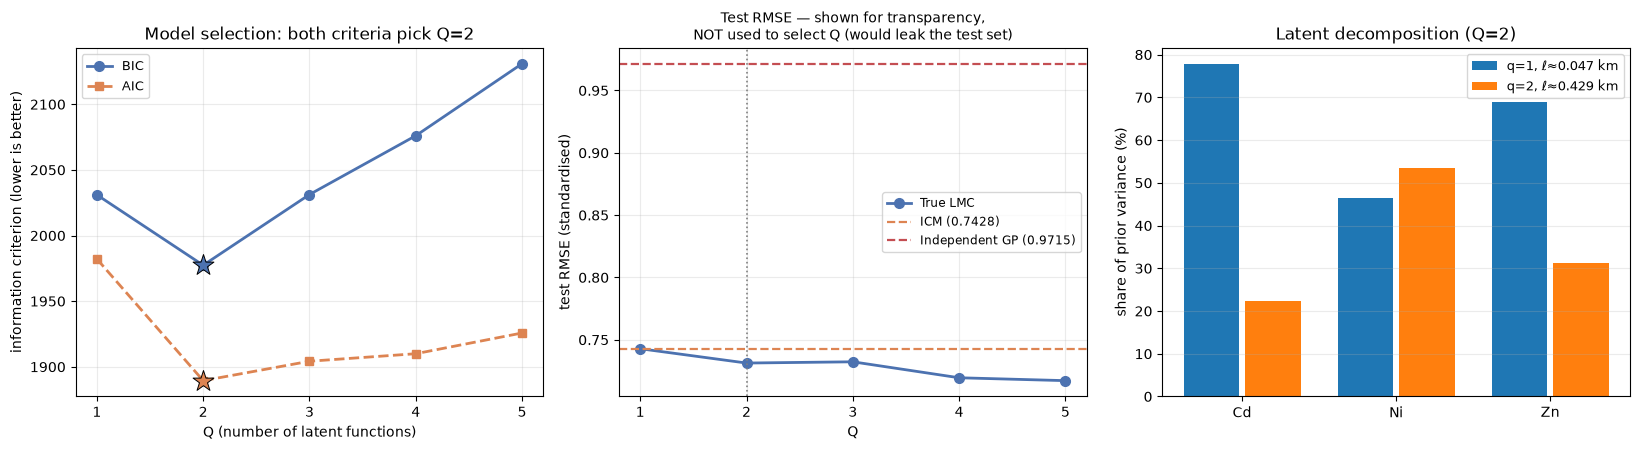

[OK] 图已保存: E:\Research\figures\true_lmc.png


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6))

# (a) BIC / AIC vs Q —— 这才是选 Q 的依据
ax = axes[0]
ax.plot(tab.Q, tab.bic, "o-", lw=2, ms=7, color="#4c72b0", label="BIC")
ax.plot(tab.Q, tab.aic, "s--", lw=2, ms=6, color="#dd8452", label="AIC")
for arr, col in [(tab.bic.to_numpy(), "#4c72b0"), (tab.aic.to_numpy(), "#dd8452")]:
    i = arr.argmin()
    ax.scatter([tab.Q.iloc[i]], [arr[i]], s=250, marker="*", color=col,
               edgecolor="k", lw=0.7, zorder=5)
ax.set_xticks(tab.Q)
ax.set_xlabel("Q (number of latent functions)")
ax.set_ylabel("information criterion (lower is better)")
ax.set_title(f"Model selection: both criteria pick Q={qb}")
ax.legend(fontsize=9); ax.grid(alpha=0.25)

# (b) 测试 RMSE —— 仅作透明展示, 不是选择依据
ax = axes[1]
ax.plot(tab.Q, tab.rmse, "o-", lw=2, ms=7, color="#4c72b0", label="True LMC")
ax.axhline(RMSE_ICM, color="#dd8452", ls="--", lw=1.6, label=f"ICM ({RMSE_ICM})")
ax.axhline(RMSE_GP, color="#c44e52", ls="--", lw=1.6, label=f"Independent GP ({RMSE_GP})")
ax.axvline(qb, color="gray", ls=":", lw=1.2)
ax.set_xticks(tab.Q)
ax.set_xlabel("Q"); ax.set_ylabel("test RMSE (standardised)")
ax.set_title("Test RMSE — shown for transparency,\nNOT used to select Q (would leak the test set)",
             fontsize=10)
ax.legend(fontsize=8.5); ax.grid(alpha=0.25)

# (c) 选定模型的潜在函数分解
ax = axes[2]
w = 0.8 / best["Q"]
for q, ls in enumerate(best["ls"]):
    frac = np.diag(best["Bs"][q]) / tot
    ax.bar(np.arange(P) + q * w, frac * 100, width=w * 0.9,
           label=f"q={q+1}, ℓ≈{ls.mean():.3f} km")
ax.set_xticks(np.arange(P) + w * (best["Q"] - 1) / 2, NAMES)
ax.set_ylabel("share of prior variance (%)")
ax.set_title(f"Latent decomposition (Q={qb})")
ax.legend(fontsize=9); ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
out = ROOT / "figures" / "true_lmc.png"
plt.savefig(out, dpi=140)     # savefig 必须在 show 之前! 早期版本反了, 存下来是空白图
plt.show()
print(f"[OK] 图已保存: {out}")

## 结论演变的记录（三个已作废的版本）

这个 notebook 先后得出过三个互相矛盾的结论。保留这段记录, 是因为报告的
"方法论反思"部分用得上 —— 但**下面三条都不要引用**。

| 轮次 | 当时的结论 | 为什么错 |
|---|---|---|
| 第 1 轮 | **Q=3**, 且 "q=3 是纯共同因子, 相关系数 0.998" | 未收敛就解读参数。加大迭代后 Q=3 的分解塌回 Q=2 的结构 |
| 第 2 轮 | **Q=2**, 用 `best_loss` 修正震荡 | `best_loss` 在 CG 随机估计下 = 挑最幸运的一次采样 |
| 第 3 轮 | **Q=4**, 按训练 loss 选最优 | 训练 loss 随参数量单调下降, 必然选到 Q_max |

**教训**（值得写进报告）:

1. **解读参数之前先确认收敛。** 第 1 轮那个"相关系数 0.998 的纯共同因子"看起来
   是漂亮的地质发现, 实际是没收敛的产物。
2. **在随机估计的目标函数上取最小值是错的。** 它挑的是噪声的下尾, 不是更好的解。
3. **训练似然不能用于模型选择。** 它对参数量单调, 必须加惩罚项 (BIC/AIC) 或用
   交叉验证。

以下是修正后的结论。

## 最终结论

### 选定 Q = 2, BIC 与 AIC 一致

| Q | k | −2logML | BIC | AIC | 测试 RMSE |
|---|---|---|---|---|---|
| 1 | 10 | 1962.2 | 2031.0 | 1982.2 | 0.7428 |
| **2** | **18** | **1853.5** | **1977.4** ✓ | **1889.5** ✓ | **0.7313** |
| 3 | 26 | 1852.2 | 2031.2 | 1904.2 | 0.7323 |
| 4 | 34 | 1841.9 | 2075.9 | 1909.9 | 0.7198 |
| 5 | 42 | 1841.8 | 2130.9 | 1925.8 | 0.7172 |

BIC 在 Q=2 领先次优 53 个单位。**注意测试 RMSE 在 Q=4/5 更低 —— 但那不是选择
依据**, 用它选 Q 会泄漏测试集。BIC/AIC 判的是"增加的拟合能力是否抵得过增加的
参数": Q=1→2 用 55.1 的惩罚买到 108.7 的 misfit 改善（值）, 之后每步只买到
0.1~10.4（不值）。

**旁证**: Q=5 时第 5 个潜在函数的方差占比是 0.0% / 0.0% / 0.0% —— 优化器自己
把它关掉了。模型本身就说明了它不需要 5 个。

### 双尺度结构 —— 本研究最有内容的结果

| | ℓ_X (km) | ℓ_Y (km) | Cd | Ni | Zn | B_q 内的跨输出相关 |
|---|---|---|---|---|---|---|
| **q=1 短程** | 0.052 | 0.042 | **77.7%** | 46.5% | 68.8% | 0.67 (中等) |
| **q=2 长程** | 0.511 | 0.347 | 22.3% | **53.5%** | 31.2% | **0.88–0.94 (近乎完美)** |

**q=2 是长程共同因子**: ℓ≈0.43 km 超过规则网格间距 (0.25 km), 三个金属间相关性
高达 0.88–0.94 —— 近乎完美相关意味着它们在这个尺度上是**同一个潜在场的线性缩放**,
对应区域性地质背景（共同母岩风化）。

**q=1 是短程局部结构**: ℓ≈0.05 km, 相关性只有 0.67, 金属间差异明显, 对应局部
人为输入; 且它主导 Cd 的方差 (77.7%)。

**一个反直觉的细节**: 虽然 q=1 占 Cd 先验方差的 77.7%, 但在实际预测面上, 长程
分量 q=2 贡献了 **62.9%** 的幅度（见 `06_spatial_maps.py` 的精确可加分解,
校验残差 1.3e-12）。**先验方差占比 ≠ 后验贡献。**

### 这推翻了 03/04 的一个结论

早期认为"Cd 空间自相关弱"。**那是 ICM 单一尺度约束造成的假象** —— 长程结构一直
存在, ICM 被迫二选一时选了短程（它学到的 0.079/0.058 几乎精确落在 q=1 上）。

而 ICM 报告的单一相关性 0.743, 是 0.673 和 0.941 的加权混合 —— **一个不对应任何
真实过程的平均数**。

### 但不要声称 LMC 预测得比 ICM 好

单次划分上 LMC 比 ICM 好 1.55%，**这个差距不复现**: 10 次随机划分下 LMC 赢 5 输 5,
配对 t 检验 p=0.19（见 `07_robustness.py`）。

**LMC 的价值在可解释性, 不在预测精度。** 报告必须这样写。

---

**后续**: `06_spatial_maps.py`（空间后验图 + 潜在函数分解）→
`07_robustness.py`（10 次划分）→ `10_report_figures.py`（报告用图）